# **Project Name**    -  Yes Bank Monthly Stock Price – Exploratory Data Analysis (EDA)


##### **Project Type** - EDA
##### **Contribution** - Individual
##### **Student** - Rahul Sharma
##### **Programme** - B.Tech Information Technology (Hons.)
##### **Institution** - Panipat Institute of Engineering and Technology (PIET), Samalkha
##### **GitHub profile** - https://github.com/Mr-rxa

# **Project Summary -**

This project analyses the monthly share-price history of Yes Bank, an Indian private-sector bank, from July 2005 to November 2020: 185 monthly observations of Open, High, Low and Close prices. Yes Bank has been in the news since 2018 because of the governance and fraud case around its co-founder Rana Kapoor, so the goal of this exploratory data analysis (EDA) is to understand how the stock behaved before, during and after that period, and which patterns matter for a model that predicts the monthly closing price.

The data are clean. There are no missing values and no duplicate rows, every month between the first and last record is present, and every row obeys basic price logic (High is never below Open or Close, Low is never above them). The wrangling therefore focused on converting the 'Mon-YY' text dates into real datetimes, sorting chronologically, and engineering analysis features: year, month, monthly return, intra-month price range, 3/6/12-month moving averages, running drawdown, 12-month rolling volatility and a rise/decline era flag. The IQR rule flags nine Close values as outliers, but all of them sit in the July 2017 to August 2018 peak, so they are genuine market history and were kept.

Twenty charts follow the Univariate-Bivariate-Multivariate (UBM) structure. The price history has three phases. From 2005 to 2017 the stock grew from about 12 to over 300, roughly 30% a year to its July 2018 peak, with temporary drawdowns in 2008-09, 2011 and 2013. It peaked at a monthly close of 367.90 in July 2018 (monthly high of 404 in August 2018). Then, between September 2018 and November 2020, it lost about 96% of its value and ended at 14.67. The September 2018 close alone fell 46.6% month on month.

The raw price is strongly right-skewed (skewness 1.26) but its logarithm is almost symmetric (skewness -0.03), which supports working with logs or ratios. Monthly returns are fat-tailed (excess kurtosis 3.3): 31 of 184 months moved by more than 20%, and the share of such months rose from 12.7% before the peak to 40.7% afterwards. The average intra-month range jumped from about 21% of the opening price in the rise era to about 45% in the decline era, and the 12-month rolling volatility peaked at 32.8% in August 2020. Up-months outnumbered down-months 91 to 67 in the rise era but only 9 to 18 in the decline era, and from September 2018 the close sat below its 12-month moving average in 26 of 27 months.

Open, High, Low and Close are almost perfectly correlated (Close with Low 0.995, with High 0.985, with Open 0.978). That makes it easy to estimate a month's Close from the other three prices, but it also creates severe multicollinearity, and the spread around the fitted line widens at high prices. Seasonality is weak: calendar-month average returns are noisy and a Kruskal-Wallis test finds no significant month effect (p = 0.34).

Recommendations: treat the history as two regimes and never size risk from the full-sample average volatility; monitor the intra-month range, rolling volatility and the close-versus-12-month-average signal as early-warning indicators; model log prices or price ratios instead of raw rupee levels; and validate any model on a time-ordered split, because a random split leaks the future into the past.

# **GitHub Link -**

GitHub profile: https://github.com/Mr-rxa/Yes_Bank_Project2

# **Problem Statement**


**Yes Bank is a well-known Indian bank that has been in the news since 2018 because of the fraud case involving its co-founder Rana Kapoor. The dataset holds the monthly Open, High, Low and Close prices of the stock since its listing. Before predicting the closing price of the month, we need to understand how the price, its volatility and its relationships changed over time, and what that means for modelling and for risk monitoring.**

#### **Define Your Business Objective?**

1. Describe the stock's behaviour (trend, volatility, direction of months) in the period before and after the 2018 peak.
2. Find which variables carry information about the monthly **Close**, and identify data issues (skew, outliers, multicollinearity, heteroscedasticity) that a prediction model must handle.
3. Turn the findings into practical recommendations for risk monitoring and for the follow-up regression model.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 13})

### Dataset Loading

In [2]:
# Load Dataset
from pathlib import Path

def load_data(filename="data_YesBank_StockPrices.csv"):
    """Read the CSV (same folder, /content for Colab, or ./data) and parse the 'Mon-YY' dates."""
    candidates = [Path(filename), Path("/content") / filename, Path("data") / filename,
                  Path("/content/drive/MyDrive") / filename]
    for path in candidates:
        if path.exists():
            frame = pd.read_csv(path)
            frame["Date"] = pd.to_datetime(frame["Date"], format="%b-%y")   # e.g. 'Jul-05' -> 2005-07-01
            return frame
    raise FileNotFoundError(f"{filename} not found. Keep it next to this notebook or upload it in Colab.")

raw = load_data()

### Dataset First View

In [3]:
# Dataset First Look
display(raw.head())
display(raw.tail())

,Date,Open,High,Low,Close
0,2005-07-01,13.00,14.00,11.25,12.46
1,2005-08-01,12.58,14.88,12.55,13.42
2,2005-09-01,13.48,14.87,12.27,13.30
3,2005-10-01,13.20,14.47,12.40,12.99
4,2005-11-01,13.35,13.88,12.88,13.41


,Date,Open,High,Low,Close
180,2020-07-01,25.60,28.30,11.10,11.95
181,2020-08-01,12.00,17.16,11.85,14.37
182,2020-09-01,14.30,15.34,12.75,13.15
183,2020-10-01,13.30,14.01,12.11,12.42
184,2020-11-01,12.41,14.90,12.21,14.67


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
print(f"Rows: {raw.shape[0]}  |  Columns: {raw.shape[1]}")

Rows: 185  |  Columns: 5


### Dataset Information

In [5]:
# Dataset Info
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    185 non-null    datetime64[us]
 1   Open    185 non-null    float64       
 2   High    185 non-null    float64       
 3   Low     185 non-null    float64       
 4   Close   185 non-null    float64       
dtypes: datetime64[us](1), float64(4)
memory usage: 7.4 KB


#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
print("Duplicate rows :", raw.duplicated().sum())
print("Duplicate dates:", raw["Date"].duplicated().sum())

Duplicate rows : 0
Duplicate dates: 0


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
print(raw.isnull().sum())

Date     0
Open     0
High     0
Low      0
Close    0
dtype: int64


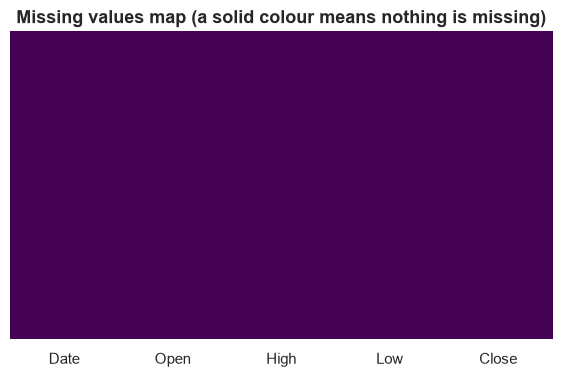

Largest gap between records (days): 31 -> every month is present
Rows where High < max(Open, Close): 0
Rows where Low  > min(Open, Close): 0


In [8]:
# Visualizing the missing values
plt.figure(figsize=(7, 4))
sns.heatmap(raw.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing values map (a solid colour means nothing is missing)")
plt.show()

# Extra integrity checks: continuous monthly calendar and basic price logic
month_gaps = raw["Date"].sort_values().diff().dt.days.dropna()
print("Largest gap between records (days):", int(month_gaps.max()), "-> every month is present")
print("Rows where High < max(Open, Close):", int((raw["High"] < raw[["Open", "Close"]].max(axis=1)).sum()))
print("Rows where Low  > min(Open, Close):", int((raw["Low"] > raw[["Open", "Close"]].min(axis=1)).sum()))

### What did you know about your dataset?

* The dataset has **185 rows and 5 columns**: a text date in `Mon-YY` format plus four numeric price columns (Open, High, Low, Close).
* It covers **every month from Jul-2005 to Nov-2020** (15 years and 5 months) with no gaps, so it is a regular monthly time series.
* There are **no missing values and no duplicate rows**, and the price logic holds in every row (High is never below Open/Close and Low is never above them).
* `Date` is stored as text and must be converted to datetime; the file is also stored oldest-first, but the code sorts it explicitly to be safe.
* Prices range from about 10 to 404 INR, so the scale changes by a factor of ~40 over the period, which is important for the later modelling.

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
print(list(raw.columns))

['Date', 'Open', 'High', 'Low', 'Close']


In [10]:
# Dataset Describe
display(raw.describe().round(2))

,Date,Open,High,Low,Close
count,185,185.00,185.00,185.00,185.00
mean,2013-03-01 19:04:12.972973,105.54,116.10,94.95,105.20
min,2005-07-01 00:00:00,10.00,11.24,5.55,9.98
25%,2009-05-01 00:00:00,33.80,36.14,28.51,33.45
50%,2013-03-01 00:00:00,62.98,72.55,58.00,62.54
75%,2017-01-01 00:00:00,153.00,169.19,138.35,153.30
max,2020-11-01 00:00:00,369.95,404.00,345.50,367.90
std,NaN,98.88,106.33,91.22,98.58


### Variables Description

| Variable | Type | Meaning |
|---|---|---|
| **Date** | datetime (month) | The month of the record, stored as text like `Jul-05` in the file |
| **Open** | float | Price at the start of the month (INR) |
| **High** | float | Highest price reached during the month (INR) |
| **Low** | float | Lowest price reached during the month (INR) |
| **Close** | float | Price at the end of the month (INR) – the **target variable** to predict |

*Note on the project brief:* the data-description table in the brief says "highest/lowest price in the day" and describes Close as "Occupations of the speaker". The second one is clearly a copy-paste error from another project, and because the file has one row per month, High and Low are the **monthly** extremes and Close is the **monthly closing price**.

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
for col in raw.columns:
    print(f"{col:<6} -> {raw[col].nunique():>3} unique values")

Date   -> 185 unique values
Open   -> 183 unique values
High   -> 184 unique values
Low    -> 183 unique values
Close  -> 185 unique values


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Write your code to make your dataset analysis ready.
PEAK_DATE = pd.Timestamp("2018-08-01")      # month of the all-time monthly high (404.0)

def prepare_data(frame):
    """Return a chronologically sorted copy of the data with all analysis features added."""
    d = frame.copy().sort_values("Date").reset_index(drop=True)

    # --- calendar features
    d["Year"] = d["Date"].dt.year
    d["Month"] = d["Date"].dt.month
    d["Month_Name"] = d["Date"].dt.strftime("%b")

    # --- return and transformation features
    d["Return"] = d["Close"].pct_change() * 100                   # month-on-month % change of Close
    d["Log_Close"] = np.log(d["Close"])                           # removes the right skew of price

    # --- candle features
    d["Range_Pct"] = (d["High"] - d["Low"]) / d["Open"] * 100     # intra-month range as % of open
    d["Direction"] = np.where(d["Close"] >= d["Open"], "Up", "Down")

    # --- trend and risk features
    for window in (3, 6, 12):
        d[f"MA{window}"] = d["Close"].rolling(window).mean()      # moving averages
    d["Gap_vs_MA6"] = (d["Close"] / d["MA6"] - 1) * 100
    d["Drawdown"] = (d["Close"] / d["Close"].cummax() - 1) * 100  # % below the running peak
    d["Vol12"] = d["Return"].rolling(12).std()                    # 12-month rolling volatility
    d["Era"] = np.where(d["Date"] <= PEAK_DATE, "Rise (Jul-05 to Aug-18)", "Decline (Sep-18 to Nov-20)")
    return d

df = prepare_data(raw)

# Outlier screening with the IQR rule (we only flag, we do not delete - see the explanation below)
for col in ["Open", "High", "Low", "Close"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    flagged = df[df[col] > upper]
    print(f"{col:<5}: {len(flagged)} values above the IQR fence ({upper:.1f}), "
          f"all between {flagged['Date'].min():%b-%Y} and {flagged['Date'].max():%b-%Y}")

print("\nNew columns:", [c for c in df.columns if c not in raw.columns])
display(df.head(3))

Open : 9 values above the IQR fence (331.8), all between Aug-2017 and Sep-2018
High : 5 values above the IQR fence (368.8), all between Jul-2017 and Aug-2018
Low  : 9 values above the IQR fence (303.1), all between Aug-2017 and Aug-2018
Close: 9 values above the IQR fence (333.1), all between Jul-2017 and Aug-2018

New columns: ['Year', 'Month', 'Month_Name', 'Return', 'Log_Close', 'Range_Pct', 'Direction', 'MA3', 'MA6', 'MA12', 'Gap_vs_MA6', 'Drawdown', 'Vol12', 'Era']


,Date,Open,High,Low,Close,Year,Month,Month_Name,Return,Log_Close,Range_Pct,Direction,MA3,MA6,MA12,Gap_vs_MA6,Drawdown,Vol12,Era
0,2005-07-01,13.00,14.00,11.25,12.46,2005,7,Jul,NaN,2.522524,21.153846,Down,NaN,NaN,NaN,NaN,0.000000,NaN,Rise (Jul-05 to Aug-18)
1,2005-08-01,12.58,14.88,12.55,13.42,2005,8,Aug,7.704655,2.596746,18.521463,Up,NaN,NaN,NaN,NaN,0.000000,NaN,Rise (Jul-05 to Aug-18)
2,2005-09-01,13.48,14.87,12.27,13.30,2005,9,Sep,-0.894188,2.587764,19.287834,Down,13.06,NaN,NaN,NaN,-0.894188,NaN,Rise (Jul-05 to Aug-18)


### What all manipulations have you done and insights you found?

**Manipulations done**
* Converted `Date` from text to datetime and sorted the rows chronologically (time-series order matters for every later step).
* Verified there are no nulls, duplicates, missing months or inconsistent High/Low values, so **no imputation or row removal was needed**.
* Engineered features: `Year`, `Month`, `Return` (month-on-month %), `Log_Close`, `Range_Pct` (intra-month range as % of Open), `Direction` (Up/Down month), moving averages (3/6/12), `Gap_vs_MA6`, `Drawdown`, `Vol12` (12-month rolling volatility) and an `Era` flag (Rise up to Aug-2018 vs Decline after).

**Insights**
* The IQR rule flags 9 Open, 5 High, 9 Low and 9 Close values, **all in Jul-2017 to Sep-2018**. These are the real bubble-peak months, not errors, so they are kept; removing them would delete the most important risk period.
* The Era split at the Aug-2018 peak gives 158 rise-era and 27 decline-era months, so statistics of the second era rest on fewer observations.
* The rolling features start with missing values (the first 11 months for the 12-month windows); that is expected and these rows are only skipped by the charts that use those features.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

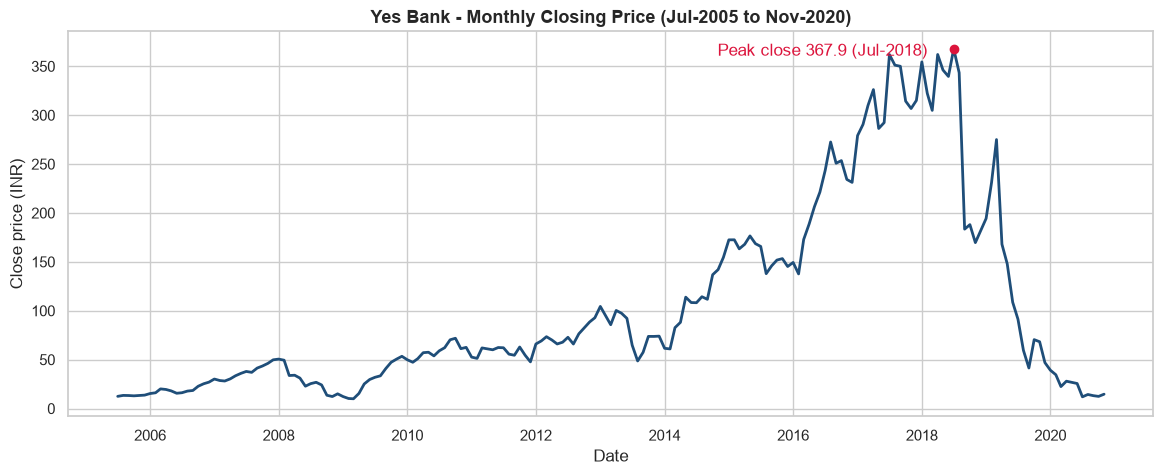

Growth Jul-05 -> peak: 29.7% a year | Last close 14.67 = -96.0% vs the peak


In [13]:
# Chart - 1 visualization code: closing price over time
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df["Date"], df["Close"], color="#1f4e79", linewidth=2)
peak = df.loc[df["Close"].idxmax()]
ax.scatter(peak["Date"], peak["Close"], color="crimson", zorder=5)
ax.annotate(f"Peak close {peak['Close']:.1f} ({peak['Date']:%b-%Y})", (peak["Date"], peak["Close"]),
            xytext=(-170, -5), textcoords="offset points", color="crimson")
ax.set(title="Yes Bank - Monthly Closing Price (Jul-2005 to Nov-2020)", xlabel="Date", ylabel="Close price (INR)")
plt.show()

cagr = (peak["Close"] / df["Close"].iloc[0]) ** (1 / ((peak["Date"] - df["Date"].iloc[0]).days / 365.25)) - 1
print(f"Growth Jul-05 -> peak: {cagr:.1%} a year | Last close {df['Close'].iloc[-1]:.2f} = "
      f"{df['Close'].iloc[-1] / peak['Close'] - 1:.1%} vs the peak")

##### 1. Why did you pick the specific chart?

A line chart is the natural choice for one variable that is observed over ordered time: it shows the trend, turning points and regime changes at a glance, which a table or histogram cannot.

##### 2. What is/are the insight(s) found from the chart?

The close grew from 12.46 (Jul-05) to a peak of 367.90 (Jul-18), roughly 30% a year, and then collapsed to 14.67 by Nov-20: about 96% below the peak and only 18% above the starting price after 15 years. Earlier falls (low of 9.98 in Mar-09, 2011, 2013) were recovered within a few years; the post-2018 fall was not.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the 13-year rise shows the franchise created large value, so a recovery story has to rest on governance and capital repair rather than on time alone. **Negative:** the Sep-2018 close alone dropped 46.6% in one month, so one governance shock removed almost half of the value. Event risk of this kind must be monitored explicitly instead of being assumed away.

#### Chart - 2

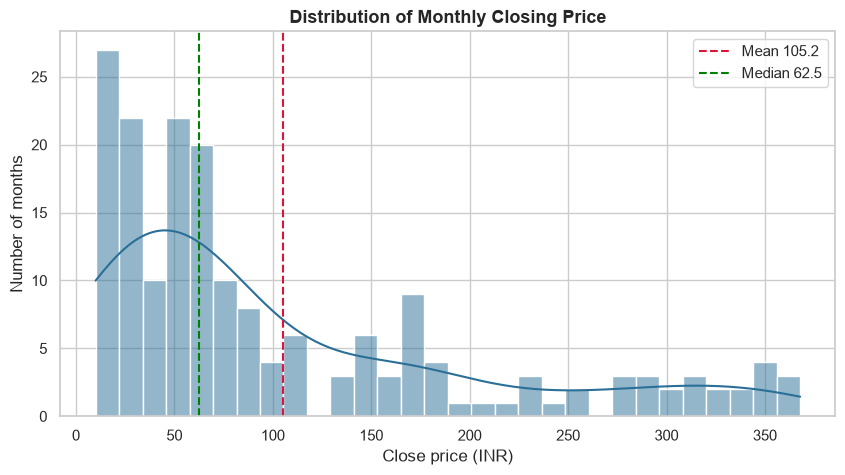

Skewness: 1.26 | months below 50: 68 | months above 250: 24


In [14]:
# Chart - 2 visualization code: distribution of the closing price
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df["Close"], bins=30, kde=True, color="#2a6f97", ax=ax)
ax.axvline(df["Close"].mean(), color="crimson", ls="--", label=f"Mean {df['Close'].mean():.1f}")
ax.axvline(df["Close"].median(), color="green", ls="--", label=f"Median {df['Close'].median():.1f}")
ax.set(title="Distribution of Monthly Closing Price", xlabel="Close price (INR)", ylabel="Number of months")
ax.legend()
plt.show()
print(f"Skewness: {df['Close'].skew():.2f} | months below 50: {(df['Close'] < 50).sum()} | months above 250: {(df['Close'] > 250).sum()}")

##### 1. Why did you pick the specific chart?

A histogram with a density curve shows the shape of the distribution, its skewness and the gap between mean and median in one view.

##### 2. What is/are the insight(s) found from the chart?

The distribution is clearly right-skewed (skewness 1.26): the mean (105.2) is far above the median (62.5). 68 of 185 months (37%) closed below 50, while only 24 months (13%) closed above 250 and all of those fall between Aug-2016 and Mar-2019.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** knowing that the price is skewed tells us to model log prices or returns and to quote medians instead of averages. **Negative:** the high-price phase lasted only about two and a half years, so benchmarks based on the average price overstate what a typical month looked like and could mislead valuation or target setting.

#### Chart - 3

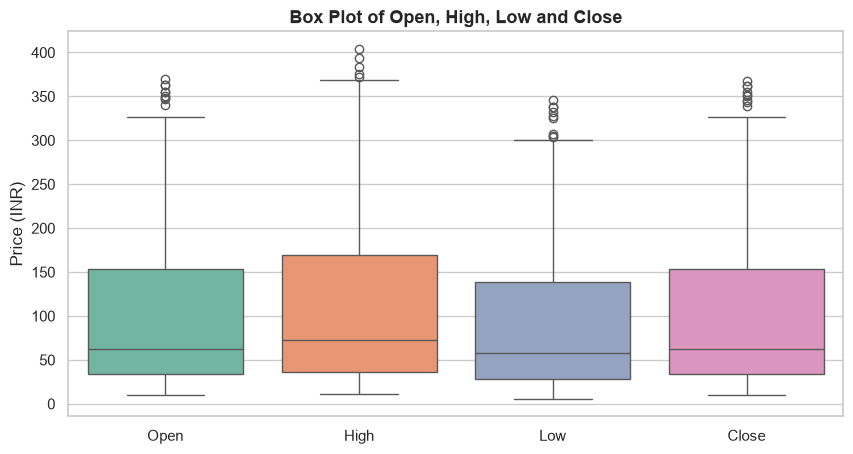

Open  median   63.0 | upper fence  331.8 | outliers: 9 (Aug-17 to Sep-18)
High  median   72.5 | upper fence  368.8 | outliers: 5 (Jul-17 to Aug-18)
Low   median   58.0 | upper fence  303.1 | outliers: 9 (Aug-17 to Aug-18)
Close median   62.5 | upper fence  333.1 | outliers: 9 (Jul-17 to Aug-18)


In [15]:
# Chart - 3 visualization code: box plot of the four price columns
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df[["Open", "High", "Low", "Close"]], ax=ax, palette="Set2")
ax.set(title="Box Plot of Open, High, Low and Close", ylabel="Price (INR)")
plt.show()

for col in ["Open", "High", "Low", "Close"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    out = df[df[col] > upper]
    print(f"{col:<5} median {df[col].median():6.1f} | upper fence {upper:6.1f} | outliers: {len(out)} "
          f"({out['Date'].min():%b-%y} to {out['Date'].max():%b-%y})")

##### 1. Why did you pick the specific chart?

A box plot compares the spread, median and outliers of several numeric columns side by side, which is exactly what is needed to screen all four price columns for data problems.

##### 2. What is/are the insight(s) found from the chart?

The four columns have almost the same shape (medians near 63, upper fences between 303 and 369). The IQR rule marks 9 Open, 5 High, 9 Low and 9 Close values as outliers, and every one of them lies between Jul-2017 and Sep-2018, the bubble-peak months, rather than being scattered randomly.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the outliers are real market history and not data-entry errors, so no correction is needed. **Negative:** these are the months just before the crash; deleting them would hide the most important risk period, so they must stay in the data and the model must cope with them, for example by using relative (ratio) features.

#### Chart - 4

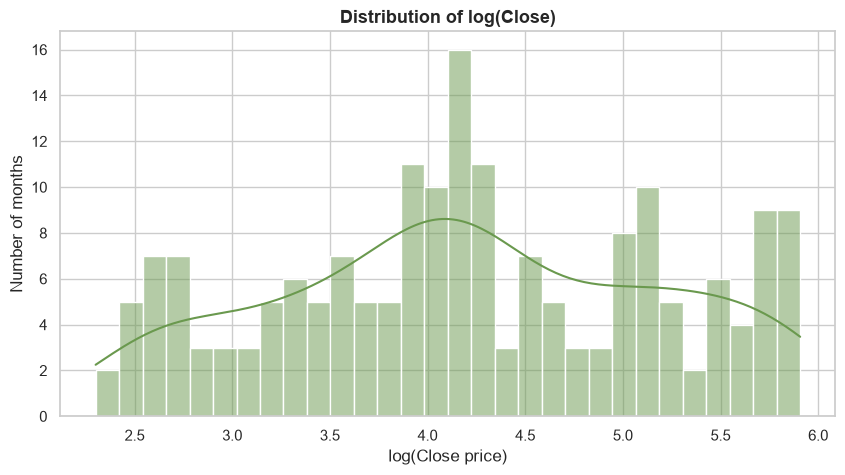

Skewness before log: 1.26 | after log: -0.03


In [16]:
# Chart - 4 visualization code: log of the closing price
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df["Log_Close"], bins=30, kde=True, color="#6a994e", ax=ax)
ax.set(title="Distribution of log(Close)", xlabel="log(Close price)", ylabel="Number of months")
plt.show()
print(f"Skewness before log: {df['Close'].skew():.2f} | after log: {df['Log_Close'].skew():.2f}")

##### 1. Why did you pick the specific chart?

After seeing the skew in Chart 2, a histogram of the log-transformed price tests whether a log transformation fixes it.

##### 2. What is/are the insight(s) found from the chart?

The skewness falls from 1.26 to -0.03, so the log price is almost perfectly symmetric. A log scale treats a 10% move the same at a price of 15 and at a price of 300, which the raw price does not.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** log prices (or price ratios) give a more stable basis for modelling and for comparing periods with very different price levels. **Negative:** the log scale hides the absolute loss; the 2018-2020 fall removed about 353 INR per share (367.90 to 14.67), which matters to real investors even though the percentage view looks tidy.

#### Chart - 5

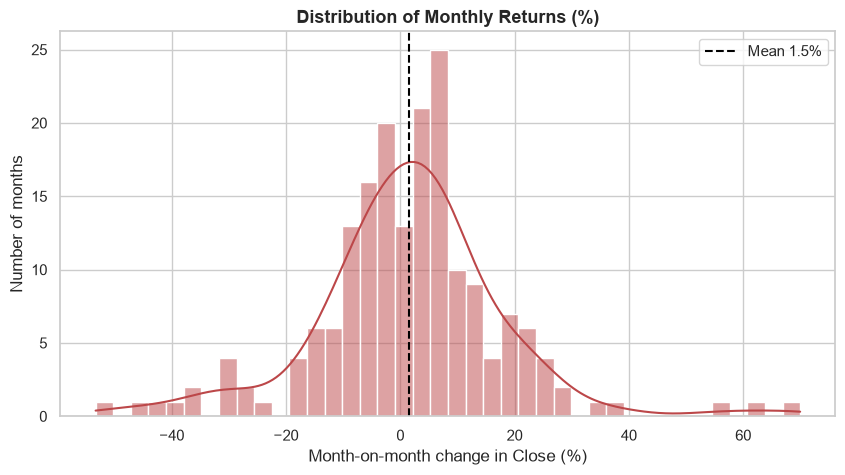

Mean 1.50% | median 2.20% | std 16.53% | excess kurtosis 3.27
Months with |return| > 20%: 31 of 184  (up: 18, down: 13)


In [17]:
# Chart - 5 visualization code: distribution of monthly returns
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df["Return"].dropna(), bins=40, kde=True, color="#bc4749", ax=ax)
ax.axvline(df["Return"].mean(), color="black", ls="--", label=f"Mean {df['Return'].mean():.1f}%")
ax.set(title="Distribution of Monthly Returns (%)", xlabel="Month-on-month change in Close (%)", ylabel="Number of months")
ax.legend()
plt.show()
r = df["Return"].dropna()
print(f"Mean {r.mean():.2f}% | median {r.median():.2f}% | std {r.std():.2f}% | excess kurtosis {r.kurt():.2f}")
print(f"Months with |return| > 20%: {(r.abs() > 20).sum()} of {len(r)}  (up: {(r > 20).sum()}, down: {(r < -20).sum()})")

##### 1. Why did you pick the specific chart?

A histogram of returns shows how large and how symmetric the month-to-month moves are, and whether the tails are heavier than a normal distribution.

##### 2. What is/are the insight(s) found from the chart?

The mean monthly return is +1.5% (median +2.2%) but the standard deviation is 16.5%, about 11 times the mean, and the excess kurtosis of 3.3 shows fat tails. 31 of 184 months moved by more than 20% (18 up, 13 down).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** sharp rebounds were possible (+70.0% in Oct-19, +62.6% in May-09). **Negative:** the typical month is dominated by noise, so point forecasts of future prices are inherently uncertain, and fat tails mean that normal-distribution risk estimates understate extreme losses such as the -53.3% in Jul-20.

#### Chart - 6

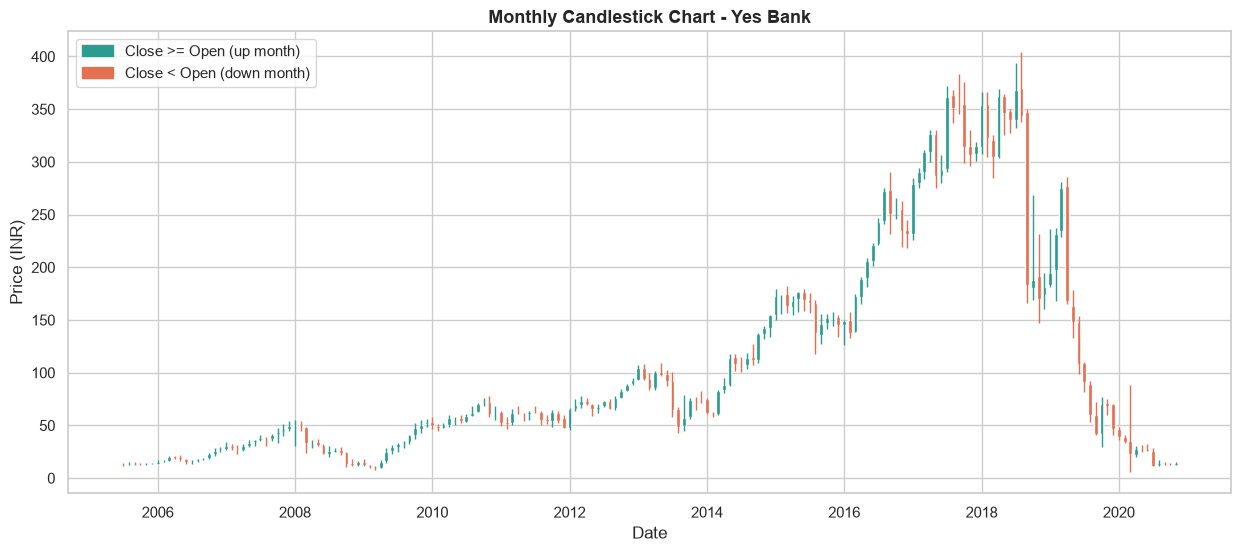

In [18]:
# Chart - 6 visualization code: monthly candlestick chart (project architecture asks for it)
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(15, 6))
up = df["Close"] >= df["Open"]
colors = np.where(up, "#2a9d8f", "#e76f51")
ax.vlines(df["Date"], df["Low"], df["High"], color=colors, linewidth=1)                 # wick = month range
ax.bar(df["Date"], (df["Close"] - df["Open"]).abs().clip(lower=0.8), bottom=df[["Open", "Close"]].min(axis=1),
       width=20, color=colors)                                                          # body = open -> close
ax.set(title="Monthly Candlestick Chart - Yes Bank", xlabel="Date", ylabel="Price (INR)")
ax.legend(handles=[Patch(color="#2a9d8f", label="Close >= Open (up month)"),
                   Patch(color="#e76f51", label="Close < Open (down month)")], loc="upper left")
plt.show()

##### 1. Why did you pick the specific chart?

A candlestick chart shows Open, High, Low and Close of every month in a single picture (body = open-to-close move, wick = full range), and it is the chart the project architecture explicitly asks for.

##### 2. What is/are the insight(s) found from the chart?

Between 2010 and 2017 the candles are small relative to the price level and the price climbs steadily, with green and red months mixed. From 2018 the candles become tall: Sep-18 has a long red body, and Mar-20 has an extreme wick (High 87.95 and Low 5.55 in the same month).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the calm 2010-2017 candles show a long phase in which holding with the trend worked. **Negative:** the tall wicks after 2018 show that prices inside the month swung far more than the month-end close reveals, so monitoring only closing prices understates risk; intra-month stop-losses or range monitoring are needed.

#### Chart - 7

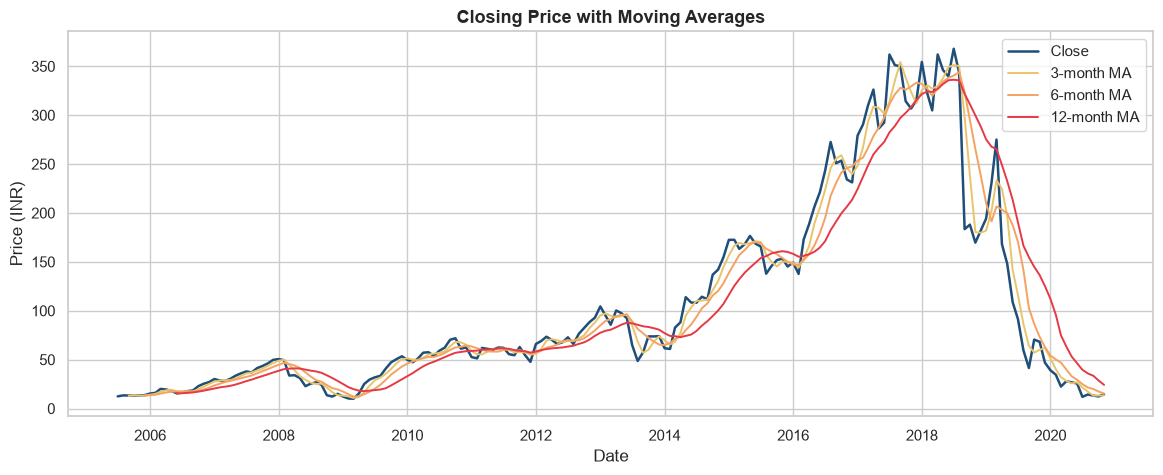

Decline (Sep-18 to Nov-20)  : close below its 12-month average in 26 of 27 months (96%)
Rise (Jul-05 to Aug-18)     : close below its 12-month average in 40 of 147 months (27%)


In [19]:
# Chart - 7 visualization code: close with 3/6/12-month moving averages
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df["Date"], df["Close"], label="Close", color="#1f4e79", linewidth=1.8)
for window, color in zip((3, 6, 12), ("#e9c46a", "#f4a261", "#e63946")):
    ax.plot(df["Date"], df[f"MA{window}"], label=f"{window}-month MA", color=color, linewidth=1.4)
ax.set(title="Closing Price with Moving Averages", xlabel="Date", ylabel="Price (INR)")
ax.legend()
plt.show()

valid = df.dropna(subset=["MA12"])
below = valid["Close"] < valid["MA12"]
for era, grp in valid.groupby("Era"):
    print(f"{era:<28}: close below its 12-month average in {below[grp.index].sum()} of {len(grp)} months ({below[grp.index].mean():.0%})")

##### 1. Why did you pick the specific chart?

Moving averages smooth out monthly noise and show the direction of the trend; the project architecture lists them explicitly, and close-versus-average is also a simple rule-based signal.

##### 2. What is/are the insight(s) found from the chart?

In the rise era the close was below its 12-month average in only 27% of months, while after the peak it was below it in 26 of 27 months (96%). The first break below the 12-month average came in Sep-2018, the month of the 46.6% drop.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a simple 'close below the 12-month average' rule marks the regime change immediately and could be used as a trigger to review exposure. **Negative:** the signal arrived at the end of the month in which the price had already fallen from 343 to 183, so moving averages lag and could not have avoided the first loss.

#### Chart - 8

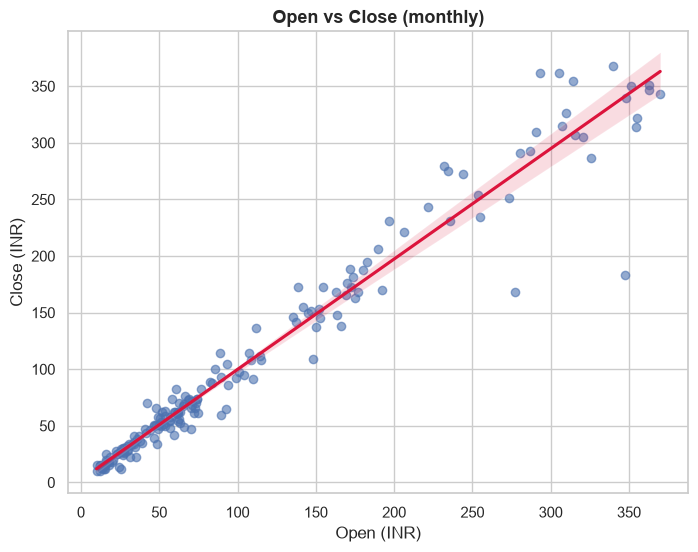

Correlation 0.978 | slope 0.98 | mean |Close/Open - 1| = 11.5%
Std of residuals by price level:
 Close
lowest third      5.7
middle third     10.0
highest third    33.6


In [20]:
# Chart - 8 visualization code: Open vs Close
fig, ax = plt.subplots(figsize=(8, 6))
sns.regplot(x="Open", y="Close", data=df, scatter_kws={"alpha": 0.6}, line_kws={"color": "crimson"}, ax=ax)
ax.set(title="Open vs Close (monthly)", xlabel="Open (INR)", ylabel="Close (INR)")
plt.show()

slope, intercept = np.polyfit(df["Open"], df["Close"], 1)
resid = df["Close"] - (slope * df["Open"] + intercept)
terciles = pd.qcut(df["Close"], 3, labels=["lowest third", "middle third", "highest third"])
print(f"Correlation {df['Open'].corr(df['Close']):.3f} | slope {slope:.2f} | mean |Close/Open - 1| = {(df['Close'] / df['Open'] - 1).abs().mean():.1%}")
print("Std of residuals by price level:\n", resid.groupby(terciles).std().round(1).to_string())

##### 1. Why did you pick the specific chart?

A scatter plot with a regression line is the standard way to examine a numeric-numeric relationship, here between the opening price and the closing price.

##### 2. What is/are the insight(s) found from the chart?

The relationship is almost a straight line with slope 0.98 and correlation 0.978. The spread around the line is not constant: the residual standard deviation is 5.7 for the lowest third of prices, 10.0 for the middle third and 33.6 for the highest third. A typical month still moves 11.5% between open and close.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the opening price is a strong anchor for the closing price and a natural model input. **Negative:** the spread widens as prices rise (heteroscedasticity), so absolute errors will always be biggest in high-price months; models should work with ratios or logs so that every period is judged fairly.

#### Chart - 9

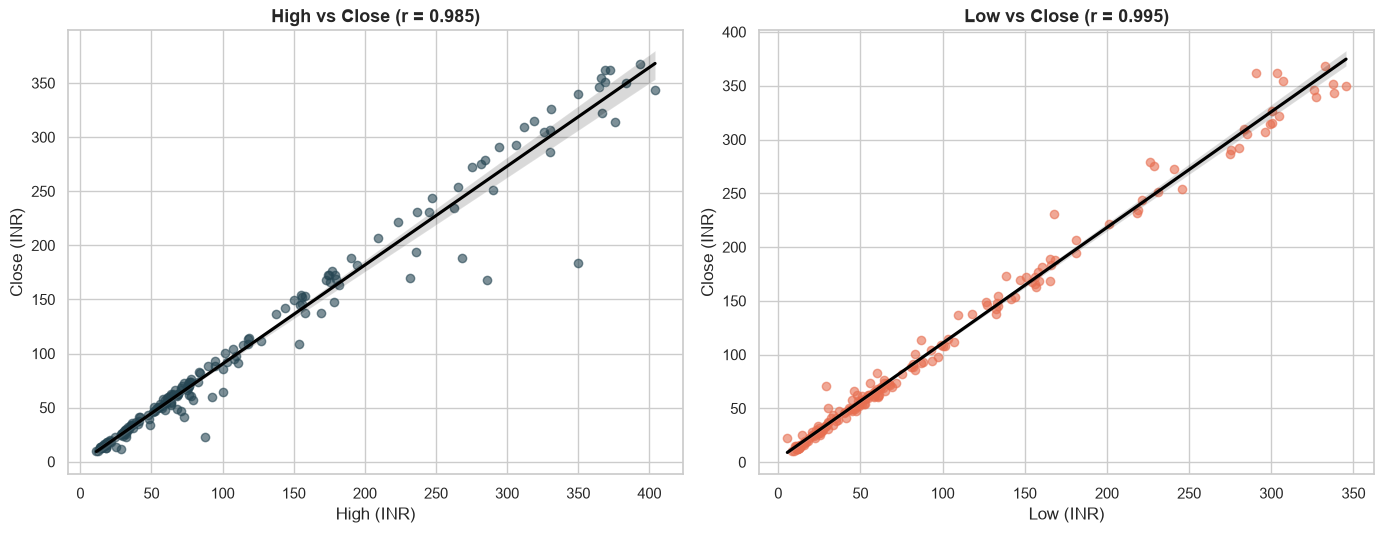

In [21]:
# Chart - 9 visualization code: High vs Close and Low vs Close
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, col, color in zip(axes, ["High", "Low"], ["#264653", "#e76f51"]):
    sns.regplot(x=col, y="Close", data=df, scatter_kws={"alpha": 0.6, "color": color}, line_kws={"color": "black"}, ax=ax)
    ax.set(title=f"{col} vs Close (r = {df[col].corr(df['Close']):.3f})", xlabel=f"{col} (INR)", ylabel="Close (INR)")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Two side-by-side scatter plots with the same y-axis make it easy to compare how tightly the monthly High and the monthly Low track the closing price.

##### 2. What is/are the insight(s) found from the chart?

Both relationships are very tight: Low vs Close has r = 0.995 (the strongest of all pairs) and High vs Close has r = 0.985. The largest departures are crash months where the High is far above the Close, for example Mar-20 (High 87.95, Close 22.45).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** once a month's High and Low are known, the Close can be estimated very accurately, which supports an in-month estimation model. **Negative:** the High and Low of a month are only known at the end of that month, so they cannot be used to forecast the Close of a future month; the business must not confuse estimation with forecasting.

#### Chart - 10

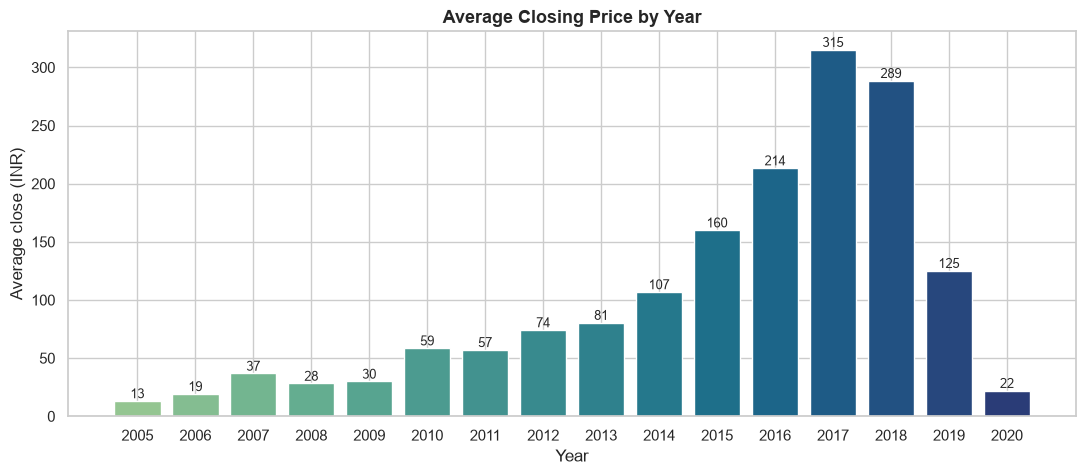

2017 average 315.3 -> 2020 average 22.1 (-93%)


In [22]:
# Chart - 10 visualization code: average close by year
yearly = df.groupby("Year")["Close"].mean()
fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(yearly.index.astype(str), yearly.values, color=sns.color_palette("crest", len(yearly)))
ax.bar_label(bars, fmt="%.0f", fontsize=9)
ax.set(title="Average Closing Price by Year", xlabel="Year", ylabel="Average close (INR)")
plt.show()
print(f"2017 average {yearly[2017]:.1f} -> 2020 average {yearly[2020]:.1f} ({yearly[2020] / yearly[2017] - 1:.0%})")

##### 1. Why did you pick the specific chart?

A bar chart compares a numeric summary (average price) across a categorical variable (year) and makes level changes between years easy to read.

##### 2. What is/are the insight(s) found from the chart?

The yearly average rises in almost every year from 13.2 (2005) to 315.3 (2017), then falls to 288.6 (2018), 125.3 (2019) and only 22.1 in 2020 (to Nov), roughly the level of 2006. The 2008 and 2011 dips were small compared with the 2019-2020 collapse.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the average price in 2017 was about 24 times that of 2005, evidence of strong long-run value creation. **Negative:** two years (2019-2020) erased 93% of the 2017 average price, so long-term holders of the stock saw a decade of gains disappear.

#### Chart - 11

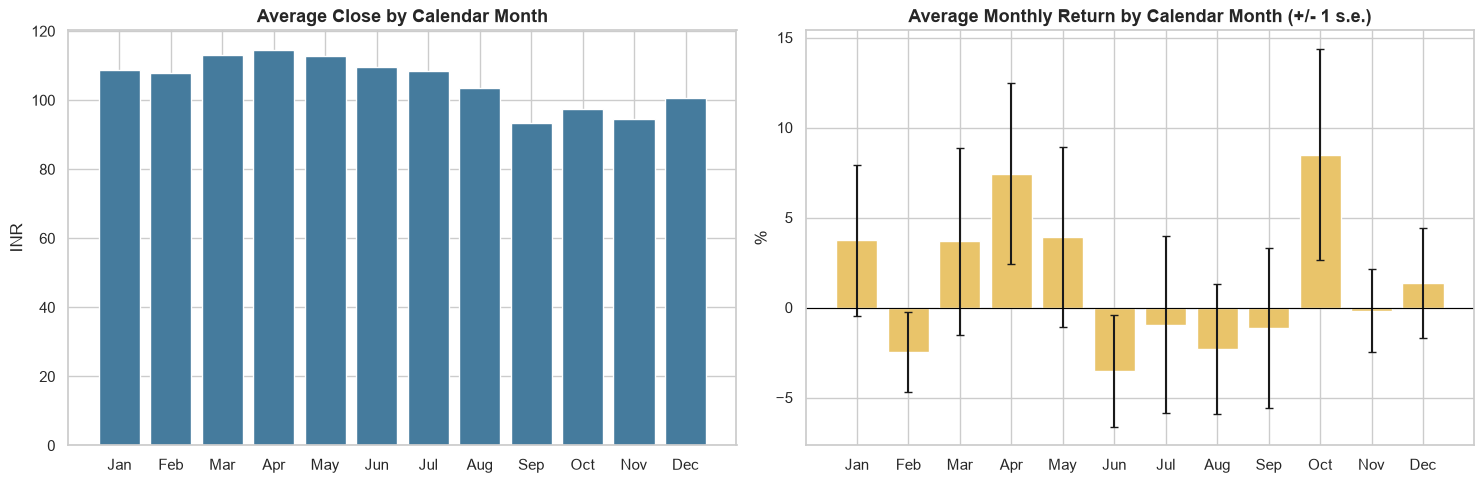

Kruskal-Wallis test for a month effect on returns: H = 12.38, p = 0.336


In [23]:
# Chart - 11 visualization code: calendar-month effects
by_month = df.groupby("Month_Name", sort=False)
order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
avg_close = df.groupby("Month_Name")["Close"].mean().reindex(order)
avg_ret = df.groupby("Month_Name")["Return"].mean().reindex(order)
sem_ret = df.groupby("Month_Name")["Return"].sem().reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(order, avg_close.values, color="#457b9d")
axes[0].set(title="Average Close by Calendar Month", ylabel="INR")
axes[1].bar(order, avg_ret.values, yerr=sem_ret.values, color="#e9c46a", capsize=3)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(title="Average Monthly Return by Calendar Month (+/- 1 s.e.)", ylabel="%")
plt.tight_layout()
plt.show()

groups = [g["Return"].dropna().values for _, g in df.groupby("Month")]
print("Kruskal-Wallis test for a month effect on returns: H = %.2f, p = %.3f" % stats.kruskal(*groups))

##### 1. Why did you pick the specific chart?

Bar charts by calendar month (numeric by categorical) are the simplest check for seasonality, and showing standard-error bars prevents us from over-reading small differences.

##### 2. What is/are the insight(s) found from the chart?

Average close only varies between about 93 (Sep) and 114 (Apr), and the average return by month ranges from -3.5% (Jun) to +8.5% (Oct). But every month's standard error is 2 to 6 percentage points, and a Kruskal-Wallis test gives p = 0.34, so there is no statistically reliable seasonality.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** calendar-month rules are not needed in the model, which keeps it simpler and more robust. **Negative:** a strategy built on 'October is strong' would rest on noise (about 15 observations per month) and could lose money, so the apparent pattern should not be used for decisions.

#### Chart - 12

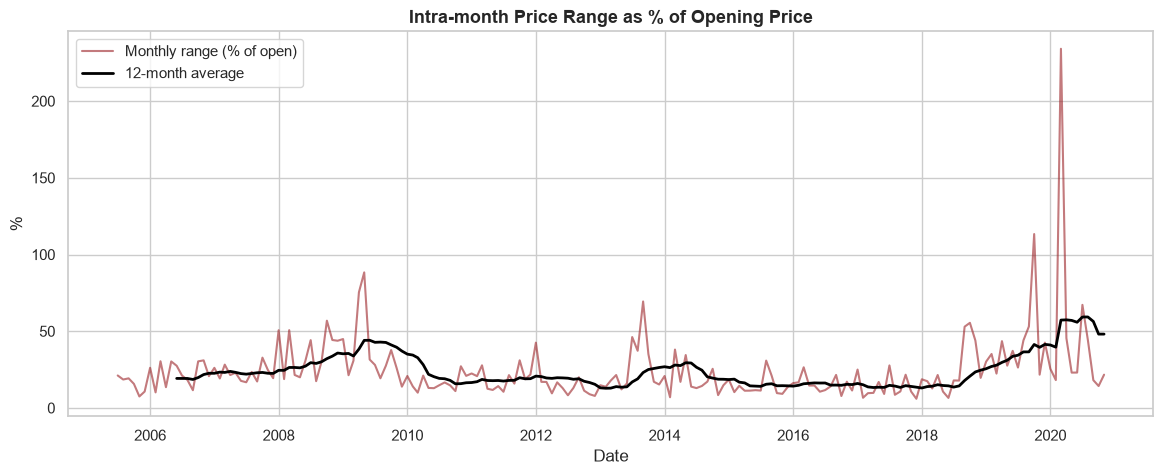

Year
2005    15.5
2006    22.6
2007    22.5
2008    35.8
2009    37.1
2010    16.4
2011    19.1
2012    15.4
2013    26.3
2014    18.7
2015    14.4
2016    15.2
2017    13.5
2018    24.6
2019    41.4
2020    48.6
Largest range: {'Date': Timestamp('2020-03-01 00:00:00'), 'Range_Pct': 234.0909090909091}


In [24]:
# Chart - 12 visualization code: intra-month range (volatility proxy)
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df["Date"], df["Range_Pct"], color="#9b2226", alpha=0.6, label="Monthly range (% of open)")
ax.plot(df["Date"], df["Range_Pct"].rolling(12).mean(), color="black", linewidth=2, label="12-month average")
ax.set(title="Intra-month Price Range as % of Opening Price", xlabel="Date", ylabel="%")
ax.legend()
plt.show()
print(df.groupby("Year")["Range_Pct"].mean().round(1).to_string())
print("Largest range:", df.loc[df["Range_Pct"].idxmax(), ["Date", "Range_Pct"]].to_dict())

##### 1. Why did you pick the specific chart?

A line chart of the monthly (High minus Low) range, scaled by the open, tracks volatility over time with a measure that is observable every month and comparable across price levels.

##### 2. What is/are the insight(s) found from the chart?

The mean range is 24.3% of the opening price. It was lowest in 2017 (13.5%), had already risen to 24.6% in 2018, and reached 41.4% in 2019 and 48.6% in 2020; the largest single month is Mar-20 at 234%.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the range is a simple early-warning indicator: it nearly doubled from 2017 to 2018, before the biggest losses of 2019. **Negative:** with monthly ranges of 40-50% the stock is effectively unusable for risk-averse investors, hedging and liquidity costs rise, and any model errors will be larger in this period.

#### Chart - 13

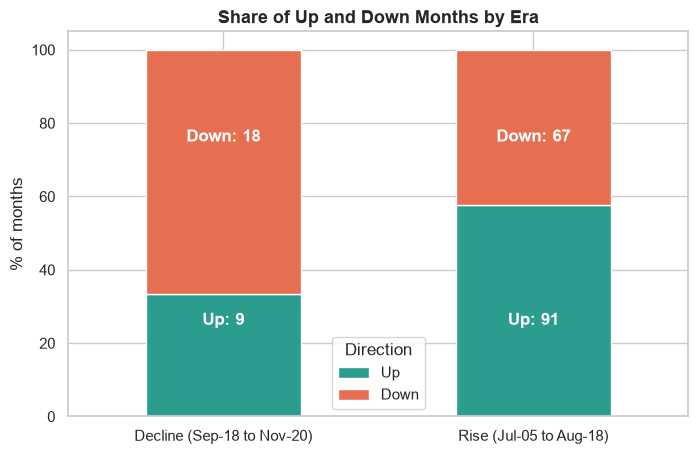

Direction                   Up  Down
Era                                 
Decline (Sep-18 to Nov-20)   9    18
Rise (Jul-05 to Aug-18)     91    67


In [25]:
# Chart - 13 visualization code: up vs down months by era
counts = pd.crosstab(df["Era"], df["Direction"])[["Up", "Down"]]
shares = counts.div(counts.sum(axis=1), axis=0) * 100
ax = shares.plot(kind="bar", stacked=True, color=["#2a9d8f", "#e76f51"], figsize=(8, 5), rot=0)
for i, (era, row) in enumerate(counts.iterrows()):
    ax.text(i, 25, f"Up: {row['Up']}", ha="center", color="white", fontweight="bold")
    ax.text(i, 75, f"Down: {row['Down']}", ha="center", color="white", fontweight="bold")
ax.set(title="Share of Up and Down Months by Era", xlabel="", ylabel="% of months")
plt.show()
print(counts)

##### 1. Why did you pick the specific chart?

A stacked bar chart is the clearest way to compare the proportion of a categorical outcome (up month vs down month) across two categories (eras).

##### 2. What is/are the insight(s) found from the chart?

In the rise era 91 of 158 months were up months (58%). In the decline era only 9 of 27 were up (33%) and 18 were down months.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** in the rise era the odds favoured the holder: more than half of the months were positive. **Negative:** in the decline era two of every three months lost money, a persistent negative momentum which shows that buy-and-hold was punished, and which no single good month could repair.

#### Chart - 14 - Correlation Heatmap

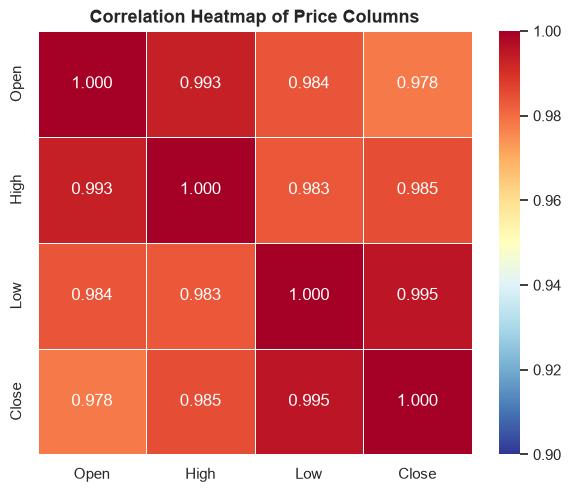

VIF: {'Open': np.float64(81.9), 'High': np.float64(79.2), 'Low': np.float64(34.6)} (above 10 signals serious multicollinearity)


In [26]:
# Correlation Heatmap visualization code
price_cols = ["Open", "High", "Low", "Close"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[price_cols].corr(), annot=True, fmt=".3f", cmap="RdYlBu_r", vmin=0.9, vmax=1, linewidths=0.5)
plt.title("Correlation Heatmap of Price Columns")
plt.show()

# Variance Inflation Factor: how strongly each predictor is explained by the other predictors
X = np.column_stack([np.ones(len(df)), df[["Open", "High", "Low"]].values])
vif = {c: variance_inflation_factor(X, i + 1) for i, c in enumerate(["Open", "High", "Low"])}
print("VIF:", {k: round(v, 1) for k, v in vif.items()}, "(above 10 signals serious multicollinearity)")

##### 1. Why did you pick the specific chart?

A heatmap condenses all pairwise correlations into one matrix, so strong relationships and the best candidate predictors are visible immediately.

##### 2. What is/are the insight(s) found from the chart?

All pairs are above 0.97: Close-Low 0.995 is the highest, Open-High 0.993, Close-High 0.985 and Close-Open 0.978. The variance inflation factors of Open, High and Low as predictors (about 82, 79 and 35) are far above the usual limit of 10, which means severe multicollinearity.

#### Chart - 15 - Pair Plot

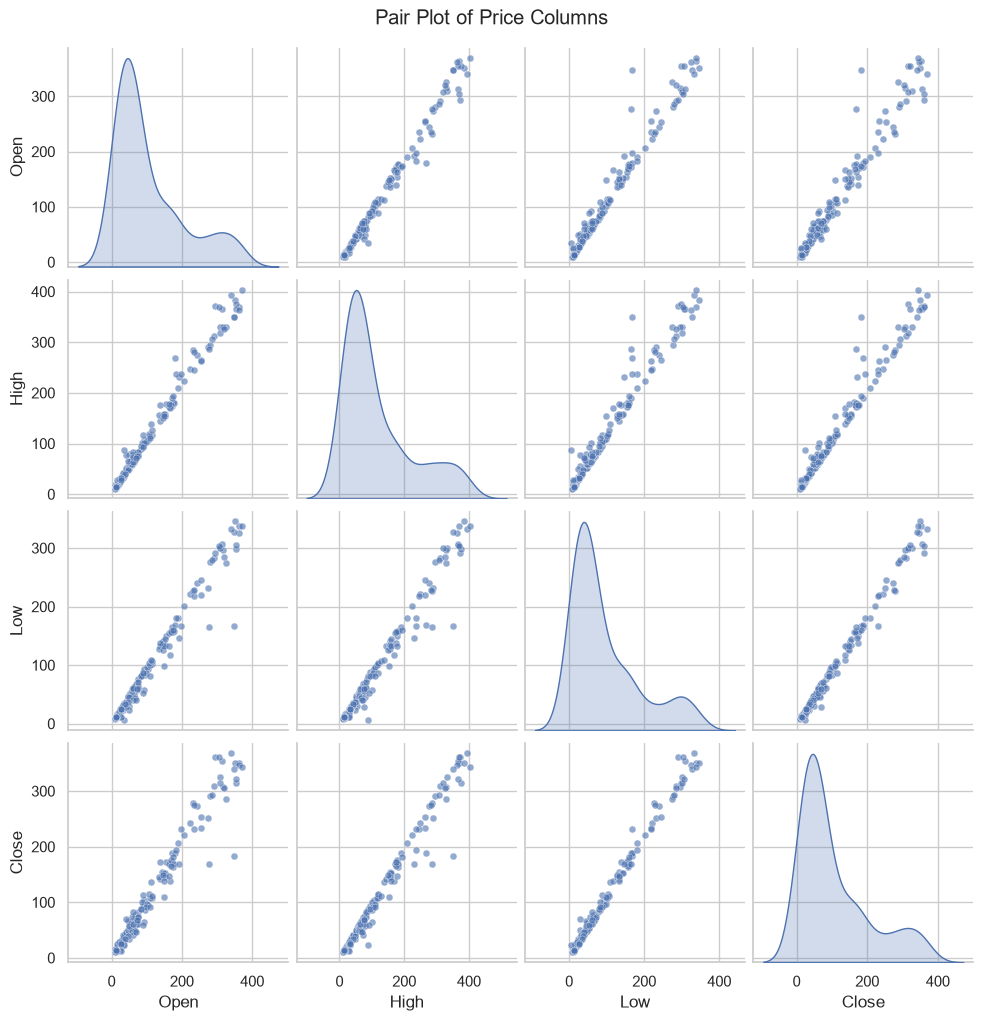

In [27]:
# Pair Plot visualization code
sns.pairplot(df[["Open", "High", "Low", "Close"]], diag_kind="kde", plot_kws={"alpha": 0.6, "s": 25})
plt.suptitle("Pair Plot of Price Columns", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every pairwise scatter plot and each variable's distribution together, which checks linearity and spread beyond what a single correlation number can say.

##### 2. What is/are the insight(s) found from the chart?

All relationships are close to linear lines through the origin, but the cloud becomes a fan: the spread widens at higher prices (the same heteroscedasticity seen in Chart 8). Every diagonal density is right-skewed with a similar shape, so the four prices behave as near copies of one another.

#### Chart - 16

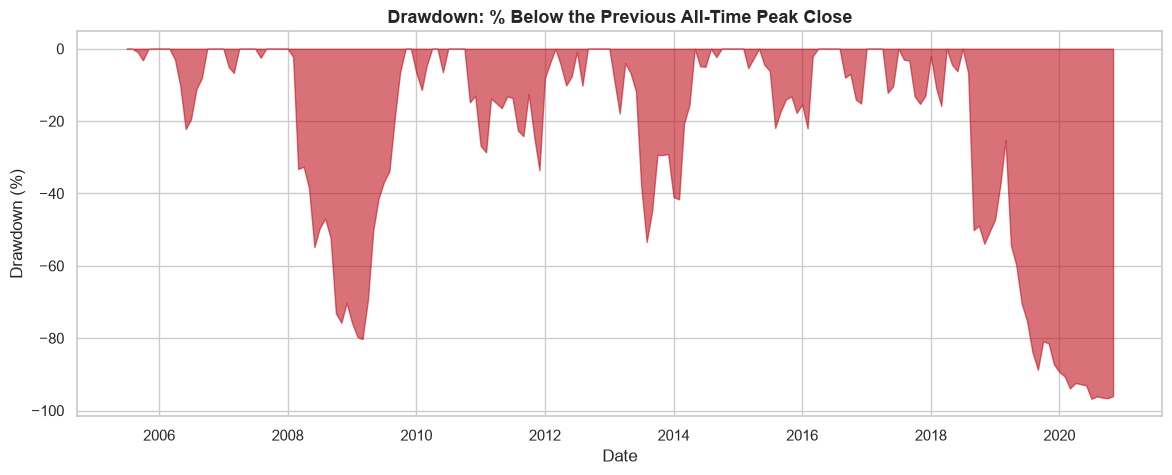

Dec-18: -50.6%
Dec-19: -87.2%
Last month: -96.0%
Deepest: -96.8 % in Jul-2020
First month below -50%: Jun-2008


In [28]:
# Chart - 16 visualization code: drawdown from the running peak
fig, ax = plt.subplots(figsize=(14, 5))
ax.fill_between(df["Date"], df["Drawdown"], 0, color="#c1121f", alpha=0.6)
ax.set(title="Drawdown: % Below the Previous All-Time Peak Close", xlabel="Date", ylabel="Drawdown (%)")
plt.show()
for label, date in [("Dec-18", "2018-12-01"), ("Dec-19", "2019-12-01"), ("Last month", "2020-11-01")]:
    print(f"{label}: {df.loc[df['Date'] == date, 'Drawdown'].iloc[0]:.1f}%")
print("Deepest:", round(df["Drawdown"].min(), 1), "% in", df.loc[df["Drawdown"].idxmin(), "Date"].strftime("%b-%Y"))
print("First month below -50%:", df.loc[df["Drawdown"] < -50, "Date"].iloc[0].strftime("%b-%Y"))

##### 1. Why did you pick the specific chart?

Drawdown, the distance below the running peak, is the standard way to show risk and 'pain' over time, and it combines price level and history in one multivariate view.

##### 2. What is/are the insight(s) found from the chart?

The drawdown had touched -50% in Jun-2008 (financial crisis) but recovered. After the 2018 peak it reached -50.6% by Dec-18, -87.2% by Dec-19 and bottomed at -96.8% in Jul-20; in the last month it is still -96.0%.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the 2008 drawdown recovered within a few years, so past crises show that deep falls can reverse when the fundamentals are repaired. **Negative:** after a 96% fall the price must rise about 25 times (+2,400%) to return to the peak, so a recovery to the old high is unrealistic and goals should be set from the current base.

#### Chart - 17

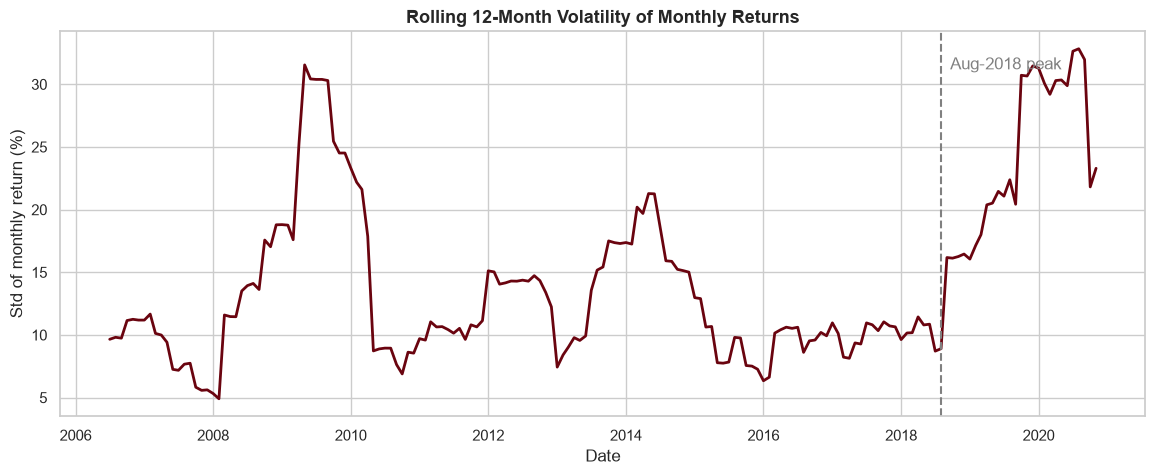

Max: 32.8% (Aug-20) | Min: 4.9% (Feb-08)
Std of monthly returns by era:
 Era
Decline (Sep-18 to Nov-20)    26.4
Rise (Jul-05 to Aug-18)       13.7


In [29]:
# Chart - 17 visualization code: rolling 12-month volatility of returns
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df["Date"], df["Vol12"], color="#6a040f", linewidth=2)
ax.axvline(PEAK_DATE, color="grey", ls="--")
ax.text(PEAK_DATE, df["Vol12"].max() * 0.95, "  Aug-2018 peak", color="grey")
ax.set(title="Rolling 12-Month Volatility of Monthly Returns", xlabel="Date", ylabel="Std of monthly return (%)")
plt.show()
print("Max: %.1f%% (%s) | Min: %.1f%% (%s)" % (df["Vol12"].max(), df.loc[df["Vol12"].idxmax(), "Date"].strftime("%b-%y"),
                                               df["Vol12"].min(), df.loc[df["Vol12"].idxmin(), "Date"].strftime("%b-%y")))
print("Std of monthly returns by era:\n", df.groupby("Era")["Return"].std().round(1).to_string())

##### 1. Why did you pick the specific chart?

A rolling-window statistic shows how risk itself changes through time, which a single full-sample standard deviation would hide.

##### 2. What is/are the insight(s) found from the chart?

Rolling volatility ranged from 4.9% (Feb-08) to 32.8% (Aug-20). The standard deviation of monthly returns is 13.7% before the peak and 26.4% after it, about 1.9 times higher.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** rolling volatility is a cheap monitoring metric that can be automated and reviewed monthly. **Negative:** the structural jump in risk after 2018 means that models and risk limits calibrated on the full history are too optimistic for the recent period, and prediction errors will be larger there.

#### Chart - 18

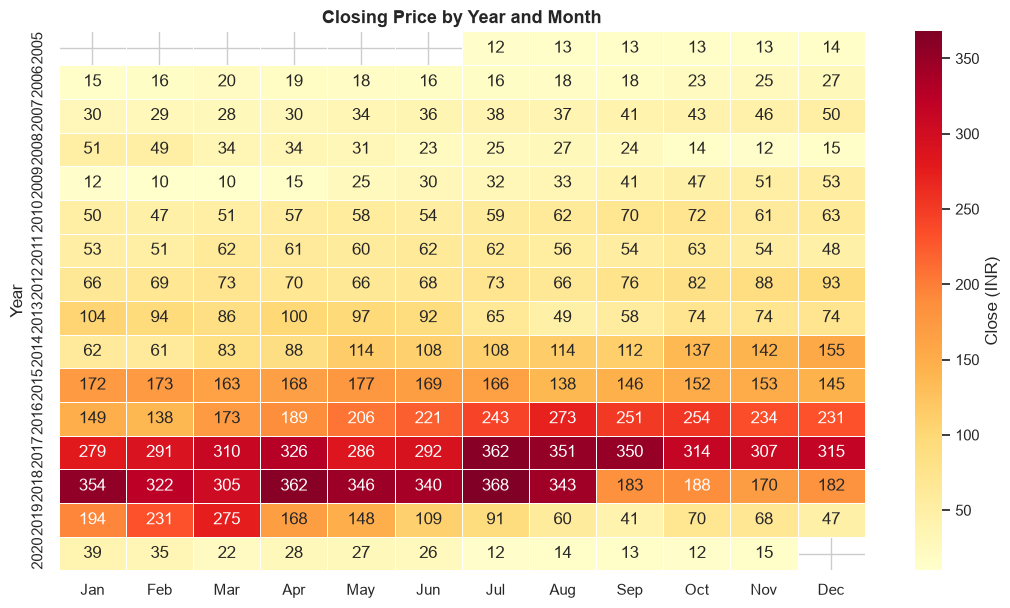

In [30]:
# Chart - 18 visualization code: Year x Month heatmap of the closing price
pivot = df.pivot(index="Year", columns="Month", values="Close")
pivot.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
plt.figure(figsize=(13, 7))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.4, cbar_kws={"label": "Close (INR)"})
plt.title("Closing Price by Year and Month")
plt.show()

##### 1. Why did you pick the specific chart?

A year-by-month heatmap places the whole timeline in one grid (two categorical axes and one numeric value), so trends along rows and seasonality down columns can both be checked at once.

##### 2. What is/are the insight(s) found from the chart?

The colour intensifies steadily through 2016-2018 (about 150 to 360), flips abruptly between Aug-18 (343) and Sep-18 (183), and fades to values below 40 across 2020. No column shows a repeating pattern across years, which confirms the absence of seasonality seen in Chart 11.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it gives non-technical stakeholders a single view of the timeline and the regime break. **Negative:** the break between Aug-18 and Sep-18 hits the whole row at once instead of gradually, so smooth trend models would not anticipate it and a model must be evaluated on that kind of jump.

#### Chart - 19

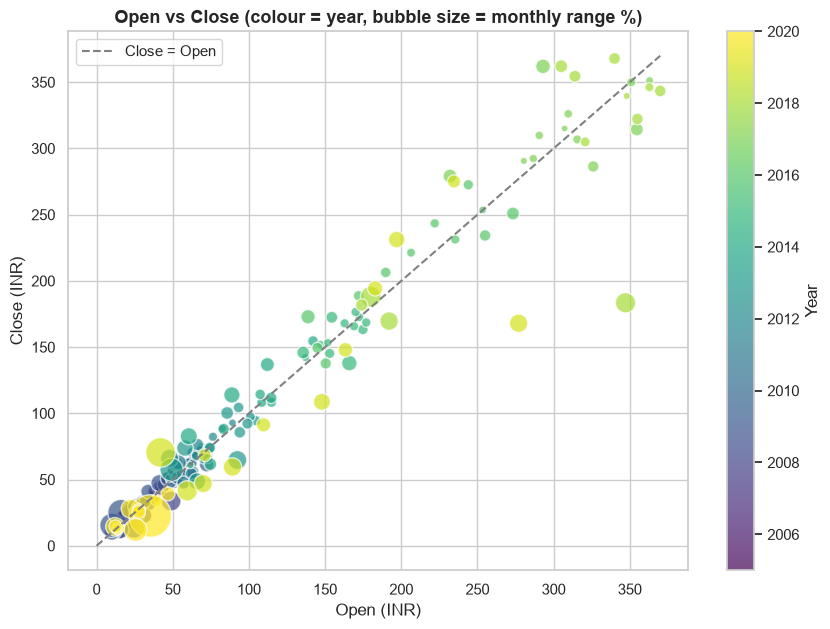

      Date  Open  High  Low  Close  Range_Pct
2020-03-01  35.2  88.0  5.6   22.4      234.1
2019-10-01  42.0  76.6 29.0   70.4      113.3
2009-05-01  15.9  28.8 14.8   25.1       88.3
2009-04-01  10.0  17.5  9.9   15.4       75.4
2013-09-01  49.2  78.9 44.8   57.5       69.4


In [31]:
# Chart - 19 visualization code: Open vs Close coloured by year, sized by monthly range
fig, ax = plt.subplots(figsize=(10, 7))
sc = ax.scatter(df["Open"], df["Close"], c=df["Year"], s=df["Range_Pct"] * 4, cmap="viridis", alpha=0.7, edgecolor="white")
plt.colorbar(sc, label="Year")
ax.plot([0, df["Open"].max()], [0, df["Open"].max()], ls="--", color="grey", label="Close = Open")
ax.set(title="Open vs Close (colour = year, bubble size = monthly range %)", xlabel="Open (INR)", ylabel="Close (INR)")
ax.legend(loc="upper left")
plt.show()
print(df.nlargest(5, "Range_Pct")[["Date", "Open", "High", "Low", "Close", "Range_Pct"]].round(1).to_string(index=False))

##### 1. Why did you pick the specific chart?

A scatter plot with colour for time and bubble size for volatility shows four variables at once (Open, Close, Year, Range), which is a true multivariate view.

##### 2. What is/are the insight(s) found from the chart?

Points follow the diagonal. Early years (dark) cluster near the origin and 2016-18 (bright) sit top right. The biggest bubbles (widest ranges) belong mostly to 2008-09 and 2019-20 and sit at low prices: crash months combine low price levels with very wide ranges.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the opening price remains a reliable anchor in every era, so the Open-Close link is stable over time. **Negative:** the big bubbles mark the months in which an Open-based estimate is least reliable, so any model should be judged separately on stressed months, not only on the average error.

#### Chart - 20

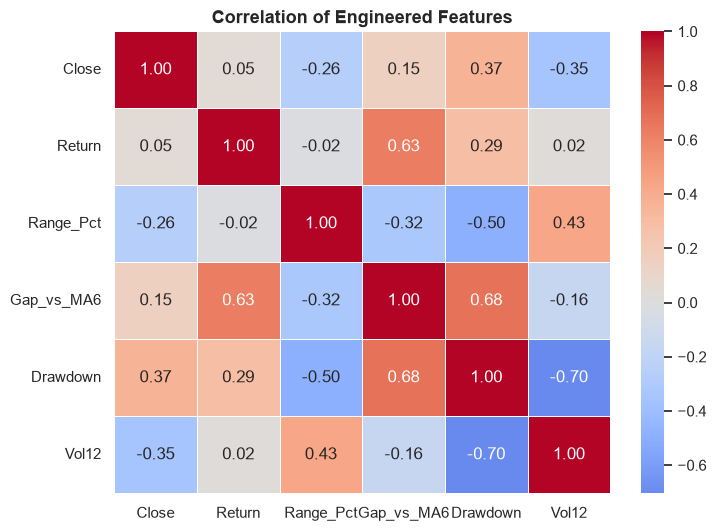

In [32]:
# Chart - 20 visualization code: correlation of engineered risk features
feat = df[["Close", "Return", "Range_Pct", "Gap_vs_MA6", "Drawdown", "Vol12"]].dropna()
plt.figure(figsize=(8, 6))
sns.heatmap(feat.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation of Engineered Features")
plt.show()

##### 1. Why did you pick the specific chart?

A second heatmap, this time on engineered features rather than raw prices, shows which risk and trend indicators move together and which are redundant.

##### 2. What is/are the insight(s) found from the chart?

Risk variables move together: Vol12 and Drawdown correlate at -0.70, Range_Pct and Drawdown at -0.50, and Return and Gap_vs_MA6 at 0.63. The price level itself is almost unrelated to the size of the monthly return (0.05) and only weakly related to the range (-0.26).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a small set of indicators (range, rolling volatility, drawdown, gap versus moving average) is enough to monitor risk, and they do not need to be tracked separately because they tell a similar story. **Negative:** the price level says almost nothing about the size of a month's move, which warns that forecasting future prices from price history alone will be hard.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

**1. Treat the history as two regimes.** The rise era (Jul-05 to Aug-18) and the decline era (Sep-18 to Nov-20) differ in trend, volatility (13.7% vs 26.4% monthly standard deviation) and direction (58% vs 33% up-months). Reports and models should never use full-sample averages as a basis for risk limits.

**2. Build a monitoring dashboard from four cheap indicators**: intra-month range (the decline-era median of 35% of the open is a useful alert level), 12-month rolling volatility (alert above roughly 20%, about 1.5 times the pre-peak level, as an illustrative threshold to be calibrated), drawdown from the running peak, and the close versus its 12-month moving average (below it for consecutive months signals a regime change). All of them are available every month without extra data.

**3. Model log prices or price ratios, not raw rupee levels.** Raw prices are skewed (1.26), the spread of errors triples between the lowest and highest price level, and Open/High/Low have VIFs of 35-82. Ratios such as log(High/Open) and log(Low/Open) remove the scale and the multicollinearity.

**4. Validate on a time-ordered split.** The series is non-stationary and has a structural break, so a random train/test split would leak future information into training and give over-optimistic scores.

**5. Be clear about estimation versus forecasting.** High and Low explain the Close almost perfectly (r = 0.985 to 0.995) but they are only known at month end, so a model that uses them estimates a month's close and does not forecast the next one. Forecasting next month's price from past prices is much harder because the price level says almost nothing about the size of a month's move (correlation 0.05 with the return).

**6. Do not use calendar-month rules.** The apparent month effects are statistically insignificant (p = 0.34).

**7. Account for event risk outside the data.** The Sep-2018 drop (-46.6%) and the extreme Mar-2020 range come from governance and regulatory events, not from price patterns. Price data alone cannot predict them; news and regulatory monitoring should complement any price model.

# **Conclusion**

The EDA of 185 monthly Yes Bank prices shows a clean, complete dataset with a dramatic story. The stock compounded at about 30% a year from 12.46 (Jul-05) to a peak close of 367.90 (Jul-18), then lost about 96% by Nov-20 (14.67), with the biggest single fall of 46.6% in Sep-18. The price is right-skewed (log price is symmetric), monthly returns are fat-tailed, and risk changed structurally after the peak: monthly return volatility rose from 13.7% to 26.4%, the intra-month range from about 21% to 45% of the open, and up-months fell from 58% to 33%. Open, High, Low and Close are almost perfectly correlated (0.978-0.995), which makes the Close easy to estimate within a month but creates severe multicollinearity (VIF 35-82) and a spread that widens with price. Calendar seasonality is not significant. These findings lead to a clear modelling plan: use log or ratio features, split the data chronologically, evaluate stressed months separately, and complement the price model with risk-monitoring indicators and event monitoring. The follow-up ML notebook implements that plan.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***